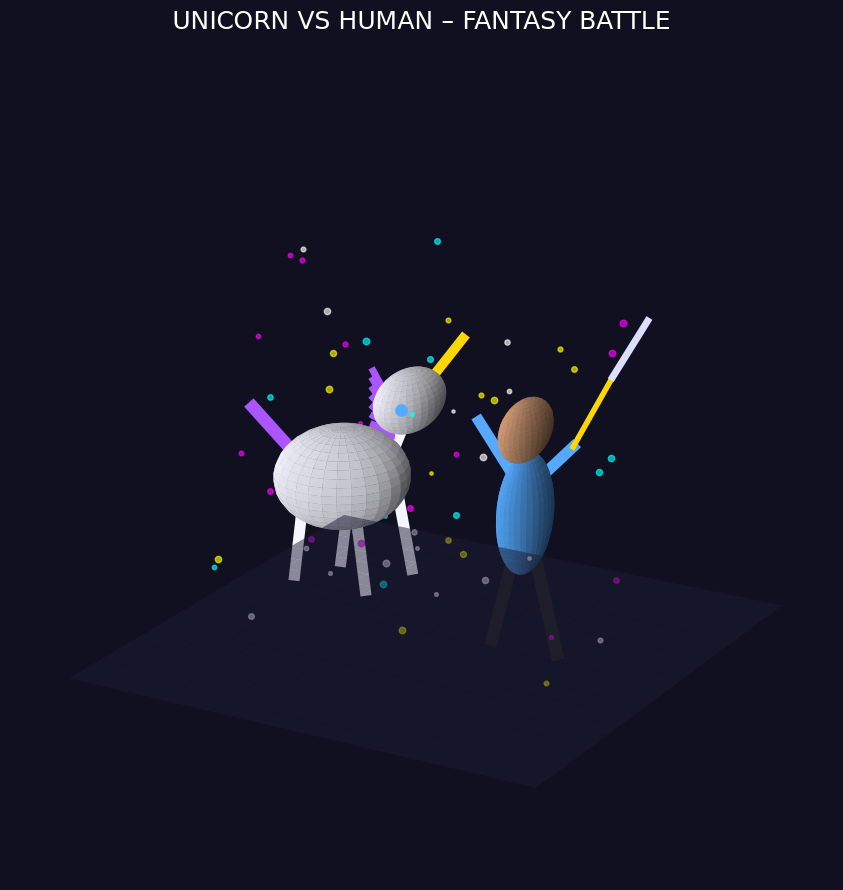

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection="3d")

fig.patch.set_facecolor("#101020")
ax.set_facecolor("#101020")

# Kolory
white = "#F5F5FF"
gold = "#FFD700"
red = "#FF3333"
blue = "#55AAFF"
black = "#222222"

# Funkcja tworząca elipsoidę
def ellipsoid(center, scale, color):
    u = np.linspace(0, 2*np.pi, 30)
    v = np.linspace(0, np.pi, 20)

    x = center[0] + scale[0]*np.outer(np.cos(u), np.sin(v))
    y = center[1] + scale[1]*np.outer(np.sin(u), np.sin(v))
    z = center[2] + scale[2]*np.outer(np.ones_like(u), np.cos(v))

    ax.plot_surface(
        x, y, z,
        color=color,
        shade=True,
        alpha=0.95
    )

# Funkcja tworząca kończyny
def limb(start, end, color, width=5):
    ax.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        [start[2], end[2]],
        color=color,
        linewidth=width
    )

# ==========================
# JEDNOROŻEC
# ==========================

# Tułów
ellipsoid((-2, 0, 2), (1.3, 0.55, 0.65), white)

# Szyja
limb((-1.1, 0, 2.3), (-0.6, 0, 3.1), white, 16)

# Głowa
ellipsoid((-0.5, 0, 3.2), (0.55, 0.4, 0.4), white)

# Róg
limb((-0.25, 0, 3.35), (0.65, 0, 4.15), gold, 7)

# Oko
ax.scatter([-0.15], [-0.37], [3.3],
           color=blue, s=65)

# Grzywa
for i in range(8):
    limb(
        (-0.9, 0, 3.1-i*0.06),
        (-1.3, 0, 3.5-i*0.12),
        "#AA55FF", 5
    )

# Nogi jednorożca
limb((-2.8, 0, 2), (-3.1, 0, 0.5), white, 8)
limb((-1.8, 0, 2), (-1.5, 0, 0.5), white, 8)
limb((-2.2, 0.3, 2), (-2.5, 0.3, 0.6), white, 8)
limb((-1.3, 0.3, 2), (-0.9, 0.3, 0.7), white, 8)

# Ogon
limb((-3.1, 0, 2.2), (-4, 0, 2.7), "#AA55FF", 9)

# ==========================
# CZŁOWIEK
# ==========================

# Tułów
ellipsoid((2, 0, 2), (0.4, 0.35, 0.8), blue)

# Głowa
ellipsoid((2, 0, 3.1), (0.35, 0.35, 0.4), "#D9A078")

# Nogi
limb((1.8, 0, 1.5), (1.3, 0, 0.2), black, 9)
limb((2.2, 0, 1.5), (2.7, 0, 0.2), black, 9)

# Ręce – pozycja bojowa
limb((1.7, 0, 2.5), (1, 0, 3.1), blue, 8)
limb((2.3, 0, 2.5), (3, 0, 3.0), blue, 8)

# Miecz
limb((3, 0, 3), (3.8, 0, 4), gold, 4)

# Ostrze miecza
limb((3.8, 0, 4), (4.5, 0, 4.8), "#DDDDFF", 5)

# ==========================
# EFEKTY MAGICZNE
# ==========================

# Magiczne iskry
np.random.seed(10)

for i in range(60):
    x = np.random.uniform(-4, 4)
    y = np.random.uniform(-0.8, 0.8)
    z = np.random.uniform(0, 5)

    ax.scatter(
        x, y, z,
        color=np.random.choice(
            ["yellow", "cyan", "magenta", "white"]
        ),
        s=np.random.uniform(5, 25),
        alpha=0.8
    )

# Podłoże
xx, yy = np.meshgrid(
    np.linspace(-5, 5, 20),
    np.linspace(-2, 2, 20)
)

zz = np.zeros_like(xx)

ax.plot_surface(
    xx, yy, zz,
    color="#252545",
    alpha=0.5
)

# ==========================
# WYGLĄD SCENY
# ==========================

ax.set_xlim(-5, 5)
ax.set_ylim(-2, 2)
ax.set_zlim(0, 5)

ax.view_init(elev=20, azim=-60)

ax.set_title(
    "UNICORN VS HUMAN – FANTASY BATTLE",
    color="white",
    fontsize=18,
    pad=20
)

ax.set_axis_off()

plt.tight_layout()
plt.show()
